# B03 — Prehedging y coberturas de M&A

**Objetivos:** cuantificar el riesgo de no cubrir una emisión futura; comparar swap forward, payer swaption y
swap contingente a la operación (*deal-contingent*); estimar el coste esperado del prehedging; resultados por
escenario de tipos y de cierre de la operación.

**Fuentes:** Myint cap. 13 y 32–34; Hull cap. 29. Datos sintéticos.

Todas las valoraciones salen del mismo modelo Hull-White (B01), así que forward, swaption y escenarios son
coherentes entre sí.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.scenarios import HullWhite, pathwise_discount
from derivlab.rate_options import implied_normal_vol, bachelier

m = sample_market()
estr, eur = build_curves(m)
hw = HullWhite(estr, eur, a=0.03, sigma=0.0085)

## 1. El caso

**AeroIbérica** (ficticia) emitirá un bono de 1.000 M€ a 10 años para pagar una adquisición. La emisión se
espera dentro de 9 meses y la operación depende de la autorización de competencia: el equipo de M&A le da un
75 % de probabilidad de cierre. La tesorería quiere cubrir el 50 % del tipo (500 M€) desde hoy.

Hoy el swap a 10 años está en 2,685 %. ¿Cuánto riesgo hay si no cubre, cuánto cuesta cubrir y con qué producto?

In [2]:
T_ISSUE, YEARS, N, P_CLOSE = 0.75, 10, 500e6, 0.75
TP_MAX = 0.0060
n = 40000
x = hw.simulate(np.array([0.0, T_ISSUE]), n, seed=41)
D = pathwise_discount(estr, hw.a, hw.sigma, np.array([0.0, T_ISSUE]), x)[:, 1]
S_q, A = hw.swap_rate(T_ISSUE, x[:, 1], YEARS)
tp = TP_MAX * (1 - np.exp(-T_ISSUE / 3))
S_rw = S_q - tp                                         # real-world scenarios (B01 assumption)

spot10 = float(hw.swap_rate(0.0, np.zeros(1), YEARS)[0][0])
K_fwd = (D * A * S_q).mean() / (D * A).mean()           # forward swap rate (annuity measure)
A0 = (D * A).mean()                                      # forward annuity seen today
swaption = N * (D * A * np.maximum(S_q - K_fwd, 0)).mean()
vol_impl = implied_normal_vol(swaption / (N * A0), K_fwd, K_fwd, T_ISSUE)
print(f"CASE spot 10y swap {spot10:.3%}; 9m-forward 10y swap {K_fwd:.3%} (carry {(K_fwd - spot10) * 1e4:.1f} bp)")
print(f"CASE ATM payer swaption 9m x 10y on 500M: {swaption / 1e6:.2f} M EUR ({swaption / (N * A0) * 1e4:.1f} bp running), "
      f"implied normal vol {vol_impl * 1e4:.0f} bp")

CASE spot 10y swap 2.682%; 9m-forward 10y swap 2.766% (carry 8.5 bp)
CASE ATM payer swaption 9m x 10y on 500M: 11.13 M EUR (25.8 bp running), implied normal vol 75 bp


## 2. Paso 1: el riesgo de no cubrir

Distribución del swap a 10 años en la fecha de emisión y su impacto en el coste del bono a lo largo de su
vida (valor presente en la fecha de emisión, sobre los 500 M€ que se quieren cubrir).

percentile swap_10y_at_issue change_vs_today_bp
        5%            1.602%               -108
       50%            2.655%                 -3
       95%            3.724%               +104
CASE 95th percentile: swap 3.724% (+104 bp vs today), extra cost over the life of the bond about 46 M EUR in PV on 500M


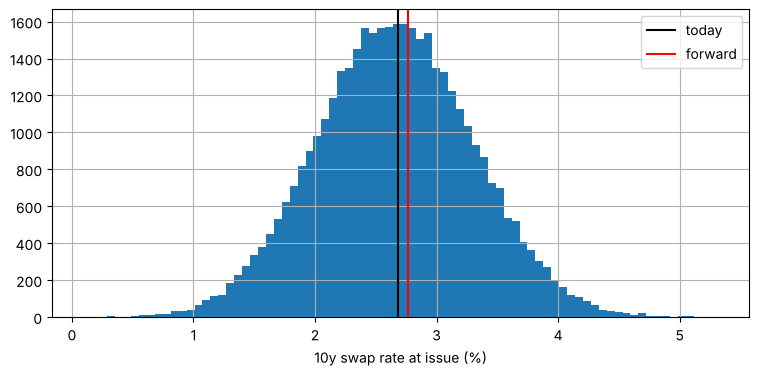

In [3]:
q = np.quantile(S_rw, [0.05, 0.5, 0.95])
pv_hit_95 = (q[2] - spot10) * N * A.mean()
risk = pd.DataFrame({"percentile": ["5%", "50%", "95%"], "swap_10y_at_issue": q,
                     "change_vs_today_bp": (q - spot10) * 1e4})
print(risk.to_string(index=False, formatters={"swap_10y_at_issue": "{:.3%}".format, "change_vs_today_bp": "{:+.0f}".format}))
print(f"CASE 95th percentile: swap {q[2]:.3%} (+{(q[2] - spot10) * 1e4:.0f} bp vs today), extra cost over the life of the bond "
      f"about {pv_hit_95 / 1e6:.0f} M EUR in PV on 500M")
plt.hist(S_rw * 100, bins=80); plt.axvline(spot10 * 100, color="k", label="today"); plt.axvline(K_fwd * 100, color="r", label="forward")
plt.xlabel("10y swap rate at issue (%)"); plt.legend(); plt.show()

## 3. Paso 2: tres soluciones

- **(a) Swap forward 9m×10y** pagador al forward. Se cancela en la emisión y su valor compensa el cupón.
- **(b) Payer swaption 9m×10y ATM-forward.** Prima pagada hoy; protege si suben y conserva las bajadas.
- **(c) Swap *deal-contingent*.** Como (a), pero desaparece si la operación no cierra. La prima contingente se
  mete en el tipo y solo se paga si cierra. Myint (cap. 34): se fija como un porcentaje de la opción ATM
  equivalente. Aquí se supone el 40 %.

Para cada escenario se calcula el **tipo efectivo** del bono cubierto (swap en la emisión menos el valor de la
cobertura por unidad de anualidad) y, si la operación no cierra, el **resultado de caja** de la cobertura.

In [4]:
CONT_SHARE = 0.40
cont_bp = CONT_SHARE * swaption / (N * A0)               # running premium added to the strike
K_dc = K_fwd + cont_bp
rng = np.random.default_rng(42)
closes = rng.random(n) < P_CLOSE

fwd_mtm = N * (S_rw - K_fwd) * A
opt_mtm = N * np.maximum(S_rw - K_fwd, 0) * A - swaption / discount_t(estr, T_ISSUE)
dc_mtm = np.where(closes, N * (S_rw - K_dc) * A, 0.0)

def effective_rate(mtm):
    return S_rw - mtm / (N * A)

out = pd.DataFrame({
    "solution": ["no hedge", "(a) forward swap", "(b) payer swaption", "(c) deal-contingent swap"],
    "eff_rate_mean": [S_rw[closes].mean(), effective_rate(fwd_mtm)[closes].mean(),
                      effective_rate(opt_mtm)[closes].mean(), effective_rate(dc_mtm)[closes].mean()],
    "eff_rate_p95": [np.quantile(S_rw[closes], 0.95), np.quantile(effective_rate(fwd_mtm)[closes], 0.95),
                     np.quantile(effective_rate(opt_mtm)[closes], 0.95), np.quantile(effective_rate(dc_mtm)[closes], 0.95)],
    "if_no_deal_mean_meur": [0.0, fwd_mtm[~closes].mean() / 1e6, opt_mtm[~closes].mean() / 1e6, 0.0],
    "if_no_deal_p5_meur": [0.0, np.quantile(fwd_mtm[~closes], 0.05) / 1e6, np.quantile(opt_mtm[~closes], 0.05) / 1e6, 0.0],
})
print(out.to_string(index=False, formatters={"eff_rate_mean": "{:.3%}".format, "eff_rate_p95": "{:.3%}".format,
                                             "if_no_deal_mean_meur": "{:+.1f}".format, "if_no_deal_p5_meur": "{:+.1f}".format}))
print(f"CASE contingent premium = {cont_bp * 1e4:.1f} bp in the strike: deal-contingent rate {K_dc:.3%}")
print(f"CASE if the deal fails, forward swap 5% worst case {np.quantile(fwd_mtm[~closes], 0.05) / 1e6:+.1f} M EUR; "
      f"swaption worst case {opt_mtm[~closes].min() / 1e6:+.1f} M EUR (the premium)")

                solution eff_rate_mean eff_rate_p95 if_no_deal_mean_meur if_no_deal_p5_meur
                no hedge        2.657%       3.724%                 +0.0               +0.0
        (a) forward swap        2.766%       2.766%                 -5.6              -54.5
      (b) payer swaption        2.708%       3.039%                 -2.5              -11.3
(c) deal-contingent swap        2.869%       2.869%                 +0.0               +0.0
CASE contingent premium = 10.3 bp in the strike: deal-contingent rate 2.869%
CASE if the deal fails, forward swap 5% worst case -54.5 M EUR; swaption worst case -11.3 M EUR (the premium)


## 4. Paso 4: el coste esperado del prehedging

Con la curva creciente, el forward está por encima del swap de hoy. Si los tipos realizados tienden a quedar
por debajo de los forwards (el supuesto de prima por plazo de B01), cubrir por adelantado tiene un coste
esperado: el forward menos el swap esperado en la emisión.

In [5]:
exp_cost_bp = (K_fwd - S_rw.mean()) * 1e4
print(f"CASE expected prehedging cost: forward {K_fwd:.3%} - expected swap at issue {S_rw.mean():.3%} = {exp_cost_bp:.1f} bp "
      f"= {exp_cost_bp * 1e-4 * N * A.mean() / 1e6:.1f} M EUR in PV on 500M")
print(f"CASE against a 95% risk of {(q[2] - spot10) * 1e4:.0f} bp, the expected cost is {exp_cost_bp / ((q[2] - spot10) * 1e4):.0%} of the risk avoided")

CASE expected prehedging cost: forward 2.766% - expected swap at issue 2.658% = 10.9 bp = 4.7 M EUR in PV on 500M
CASE against a 95% risk of 104 bp, the expected cost is 10% of the risk avoided


## 5. Contabilidad (IFRS 9)

Con contabilidad de coberturas de flujos de efectivo, la variación de valor del swap forward va a patrimonio
(OCI) y se reclasifica a resultados a lo largo de la vida del bono, ajustando su coste de intereses. Requisitos:
la emisión debe ser **altamente probable** y estar documentada con detalle. Si se retrasa dentro de la ventana
prevista, se mantiene la cobertura con algo de ineficacia. Si deja de esperarse, lo acumulado en patrimonio pasa
a resultados de inmediato. Por eso una adquisición con un 75 % de probabilidad de cierre encaja mal con un swap
forward, y bien con una swaption o un *deal-contingent*.

## 6. Comprobaciones

In [6]:
assert abs(D.mean() - discount_t(estr, T_ISSUE)) < 2e-3
assert K_fwd > spot10
fw = effective_rate(fwd_mtm)
assert np.allclose(fw, K_fwd)                     # the forward swap locks the rate in every scenario
dc_closed = effective_rate(dc_mtm)[closes]
assert np.allclose(dc_closed, K_dc)
assert out.eff_rate_p95.iloc[2] < out.eff_rate_p95.iloc[0]
assert abs(bachelier(K_fwd, K_fwd, T_ISSUE, vol_impl) * N * A0 - swaption) < 1.0
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Qué tipo efectivo obtiene AeroIbérica con el swap forward si en la emisión el swap a 10 años está en 3,50 %? ¿Y si está en 2,00 %?
2. **Intermedio.** Repite la tabla con una probabilidad de cierre del 50 %. ¿Qué solución domina ahora?
3. **Avanzado.** La emisión se retrasa a 12 meses. Calcula el nuevo forward, la swaption 12m×10y y el coste esperado del prehedging.

## Soluciones

In [7]:
print("With a forward swap the effective rate is the forward in every scenario:", f"{K_fwd:.3%}")
print(f"At 3.50%: swap gains (3.50% - {K_fwd:.3%}) x annuity; at 2.00% it loses; both net to {K_fwd:.3%}")

With a forward swap the effective rate is the forward in every scenario: 2.766%
At 3.50%: swap gains (3.50% - 2.766%) x annuity; at 2.00% it loses; both net to 2.766%


In [8]:
closes50 = rng.random(n) < 0.5
fwd_fail = fwd_mtm[~closes50]
print(f"No-deal outcome with p=50%: forward swap mean {fwd_fail.mean() / 1e6:+.1f} M, 5% worst {np.quantile(fwd_fail, 0.05) / 1e6:+.1f} M; "
      f"swaption worst {opt_mtm.min() / 1e6:+.1f} M; deal-contingent 0")
print("With a coin-flip deal, the deal-contingent swap or the swaption avoid an open position that the forward swap leaves.")

No-deal outcome with p=50%: forward swap mean -5.6 M, 5% worst -54.0 M; swaption worst -11.3 M; deal-contingent 0
With a coin-flip deal, the deal-contingent swap or the swaption avoid an open position that the forward swap leaves.


In [9]:
T2 = 1.0
x2 = hw.simulate(np.array([0.0, T2]), n, seed=43)
D2 = pathwise_discount(estr, hw.a, hw.sigma, np.array([0.0, T2]), x2)[:, 1]
S2, A2 = hw.swap_rate(T2, x2[:, 1], YEARS)
K2 = (D2 * A2 * S2).mean() / (D2 * A2).mean()
sw2 = N * (D2 * A2 * np.maximum(S2 - K2, 0)).mean()
S2_rw = S2 - TP_MAX * (1 - np.exp(-T2 / 3))
print(f"12m forward {K2:.3%}; swaption {sw2 / 1e6:.2f} M; expected prehedging cost {(K2 - S2_rw.mean()) * 1e4:.1f} bp")

12m forward 2.795%; swaption 12.76 M; expected prehedging cost 13.7 bp
